# Introduction to Python for Data Analysis

Facilitators: Furkan Kasapoğlu · Yağız Efe Korkmaz · Arda Ergene

## Guided Notebook

This notebook introduces a practical Python workflow for working with tabular data. We will move from basic Python concepts to loading, inspecting, cleaning, filtering, summarizing, and visualizing a transaction dataset.

### Learning objectives
By the end, you should be able to:
- recognize common Python data types and collections;
- load a CSV file into a pandas DataFrame;
- inspect a dataset before analysis;
- clean common data-quality issues;
- filter and select rows and columns;
- create useful summaries with pandas;
- build simple visualizations.

**Workflow:** Python basics → Load → Understand → Clean → Filter → Analyze → Visualize


## 0. Setup


In [31]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import urllib.request

In [32]:
BASE = "https://raw.githubusercontent.com/ardaergene35/python-intro/main/course/"
for f in ["transactions_raw.csv"]:
    if not os.path.exists(f):
        urllib.request.urlretrieve(BASE + f, f)
    print("Ready:", f)

Ready: transactions_raw.csv


## 1. Python basics


In [2]:
amount = 1250.50
country = "TR"
approved = True
missing_value = None

print(type(amount), type(country), type(approved), type(missing_value))


<class 'float'> <class 'str'> <class 'bool'> <class 'NoneType'>


### Lists and dictionaries


In [3]:
countries = ["TR", "US", "DE"]
transaction = {"country": "TR", "amount": 100, "status": "APPROVED"}
print(countries)
print(transaction)


['TR', 'US', 'DE']
{'country': 'TR', 'amount': 100, 'status': 'APPROVED'}


### A simple loop


In [4]:
for country in countries:
    print("Processing:", country)

Processing: TR
Processing: US
Processing: DE


## 2. Load the data


In [33]:
df = pd.read_csv("transactions_raw.csv", skipinitialspace=True, na_values=["", " ", "NA", "N/A"])
df.head()


,Card_ID,txn_date,MCC,country,amount,Channel,STATUS
0,C1113,06/06/2024,4111,FR,90.41,NaN,declined
1,C1199,19/07/2024,5812,US,$121.29,ATM,DECLINED
2,C1199,17/05/2024,5541,DE,155.87,MOTO,PENDING
3,C1086,2025-01-23,5812,TR,63.76,NaN,approved
4,C1013,2024-03-23,5999,GB,$166.68,ECOM,Approved


## 3. Understand the data


In [6]:
print("Shape:", df.shape)
print("Columns:", df.columns.tolist())


Shape: (5050, 7)
Columns: ['Card_ID ', 'txn_date', 'MCC', 'country ', 'amount ', 'Channel', 'STATUS ']


In [34]:
df.sample(5, random_state=1)

,Card_ID,txn_date,MCC,country,amount,Channel,STATUS
3960,C1136,2024-10-25,5812,AZ,$179.48,NaN,Approved
4384,C1003,2024-05-17,5541,GB,203.62,ATM,APPROVED
1796,C1160,20/06/2024,5541,US,$124.16,NaN,declined
2785,C1141,2024-05-01,5541,US,166.54,ECOM,PENDING
1675,C1113,2024-12-31,5541,IT,$-159.28,POS,Approved


In [35]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5050 entries, 0 to 5049
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   Card_ID   5002 non-null   object
 1   txn_date  5050 non-null   object
 2   MCC       5050 non-null   int64 
 3   country   5050 non-null   object
 4   amount    5050 non-null   object
 5   Channel   2880 non-null   object
 6   STATUS    5050 non-null   object
dtypes: int64(1), object(6)
memory usage: 276.3+ KB


## 4. Clean the data


### Normalize column names


In [36]:
df.columns = df.columns.str.strip().str.lower()
df.columns.tolist()

['card_id', 'txn_date', 'mcc', 'country', 'amount', 'channel', 'status']

### Convert amount to numeric


In [37]:
df["amount"] = (df["amount"].astype(str).str.replace("$", "", regex=False).str.replace(",", "", regex=False).str.strip())
df["amount"] = pd.to_numeric(df["amount"], errors="coerce")
df["amount"].describe()


count      5050.000000
mean       2360.792418
std       21587.070112
min     -232572.200000
25%          76.850000
50%         120.235000
75%         162.937500
max      248616.920000
Name: amount, dtype: float64

### Convert dates


In [38]:
df["txn_date"] = pd.to_datetime(df["txn_date"], format="mixed", dayfirst=True, errors="coerce")
df["txn_date"].head()


0   2024-06-06
1   2024-07-19
2   2024-05-17
3   2025-01-23
4   2024-03-23
Name: txn_date, dtype: datetime64[ns]

### Missing values


In [39]:
(df.isna().mean() * 100).round(2).sort_values(ascending=False)


channel     42.97
card_id      0.95
txn_date     0.00
mcc          0.00
country      0.00
amount       0.00
status       0.00
dtype: float64

In [40]:
df["channel"] = df["channel"].fillna("UNKNOWN")


### Duplicates and categories


In [41]:
print("Duplicate rows:", df.duplicated().sum())
df = df.drop_duplicates().reset_index(drop=True)
for col in ["status", "country"]:
    df[col] = df[col].str.strip().str.upper()
print(df["status"].value_counts(dropna=False))


Duplicate rows: 50
status
APPROVED    2451
DECLINED    1682
PENDING      867
Name: count, dtype: int64


## 5. Filter and select


In [42]:
df[df["amount"] > 500].head()


,card_id,txn_date,mcc,country,amount,channel,status
44,C1159,2024-08-17,5411,IT,173822.62,UNKNOWN,APPROVED
62,C1136,2024-10-06,6011,AZ,195051.57,MOTO,DECLINED
74,C1124,2024-02-28,5732,US,208634.39,ECOM,APPROVED
108,C1071,2024-06-19,5411,FR,238812.74,POS,DECLINED
243,C1077,2024-12-22,5411,DE,235662.49,UNKNOWN,APPROVED


In [43]:
df.loc[df["amount"] > 500, ["country", "amount", "status"]].head()


,country,amount,status
44,IT,173822.62,APPROVED
62,AZ,195051.57,DECLINED
74,US,208634.39,APPROVED
108,FR,238812.74,DECLINED
243,DE,235662.49,APPROVED


In [44]:
df[(df["amount"] > 500) & (df["country"] == "TR")].head()


,card_id,txn_date,mcc,country,amount,channel,status
440,C1169,2024-11-02,5812,TR,83978.58,UNKNOWN,APPROVED
490,C1006,2025-01-31,6011,TR,121717.98,UNKNOWN,DECLINED
708,C1164,2025-01-30,5732,TR,193041.00,ATM,DECLINED
950,C1118,2024-10-05,5541,TR,216304.86,POS,APPROVED
1148,C1173,2024-01-02,5411,TR,61888.39,ATM,APPROVED


In [18]:
df.query("amount > 500 and country == 'TR'").head()


,card_id,txn_date,mcc,country,amount,channel,status
440,C1169,2024-11-02,5812,TR,83978.58,UNKNOWN,APPROVED
490,C1006,2025-01-31,6011,TR,121717.98,UNKNOWN,DECLINED
708,C1164,2025-01-30,5732,TR,193041.00,ATM,DECLINED
950,C1118,2024-10-05,5541,TR,216304.86,POS,APPROVED
1148,C1173,2024-01-02,5411,TR,61888.39,ATM,APPROVED


## 6. Analyze


In [19]:
df["amount"].describe()


count      5000.000000
mean       2361.709918
std       21447.155312
min     -232572.200000
25%          76.837500
50%         120.210000
75%         163.055000
max      248616.920000
Name: amount, dtype: float64

In [45]:
df["country"].value_counts(normalize=True).mul(100).round(1)


country
FR    15.8
GB    14.9
US    14.3
AZ    14.2
TR    13.8
IT    13.7
DE    13.2
Name: proportion, dtype: float64

In [46]:
df.groupby("country")["amount"].mean().sort_values(ascending=False)


country
FR    3288.689810
AZ    2972.536329
US    2542.783026
IT    2191.922522
TR    2089.629986
DE    1858.432258
GB    1478.506850
Name: amount, dtype: float64

In [47]:
summary = (df.groupby("country").agg(transaction_count=("amount", "size"), average_amount=("amount", "mean"), total_amount=("amount", "sum")).sort_values("total_amount", ascending=False))
summary


,transaction_count,average_amount,total_amount
country,,,
FR,789,3288.689810,2594776.26
AZ,711,2972.536329,2113473.33
US,717,2542.783026,1823175.43
IT,686,2191.922522,1503658.85
TR,691,2089.629986,1443934.32
DE,660,1858.432258,1226565.29
GB,746,1478.506850,1102966.11


## 7. Visualize


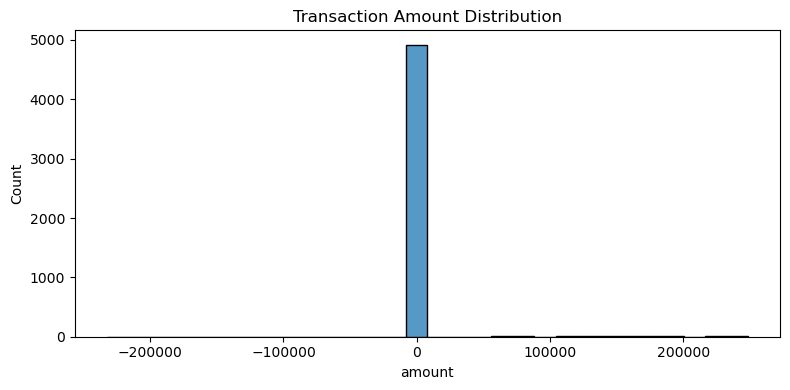

In [48]:
plt.figure(figsize=(8, 4))
sns.histplot(df["amount"].dropna(), bins=30)
plt.title("Transaction Amount Distribution")
plt.tight_layout()
plt.show()


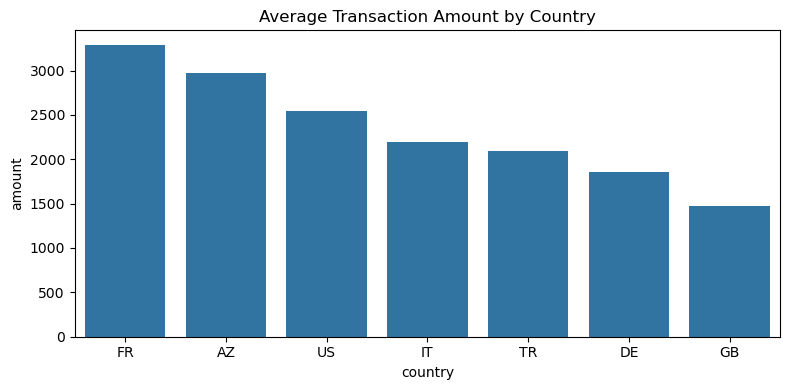

In [49]:
country_summary = df.groupby("country", as_index=False)["amount"].mean().sort_values("amount", ascending=False)
plt.figure(figsize=(8, 4))
sns.barplot(data=country_summary, x="country", y="amount")
plt.title("Average Transaction Amount by Country")
plt.tight_layout()
plt.show()


## 8. A few useful pandas patterns
The following patterns are useful extensions of the core workflow and are included for reference and practice.


### Check category values including missing values
By default, `value_counts()` excludes missing values. `dropna=False` makes them visible.


In [50]:
df["channel"].value_counts(dropna=False)


channel
UNKNOWN    2152
ECOM        728
ATM         716
MOTO        715
POS         689
Name: count, dtype: int64

### Compare two categorical variables
A cross-tabulation is a quick way to compare category distributions.


In [51]:
pd.crosstab(
    df["country"],
    df["status"],
    normalize="index"
).mul(100).round(1)


status,APPROVED,DECLINED,PENDING
country,,,
AZ,51.3,31.6,17.0
DE,47.1,33.2,19.7
FR,53.7,31.7,14.6
GB,51.1,32.0,16.9
IT,46.5,37.0,16.5
TR,47.3,33.4,19.2
US,45.2,36.8,18.0


### Create a pivot table
`pivot_table` is useful when you want to summarize a numeric variable across two dimensions.


In [52]:
pd.pivot_table(
    df,
    index="country",
    columns="channel",
    values="amount",
    aggfunc="mean"
).round(2)


channel,ATM,ECOM,MOTO,POS,UNKNOWN
country,,,,,
AZ,1213.75,3189.31,3069.20,1423.82,3955.01
DE,1720.39,6861.55,1000.05,111.73,897.33
FR,3070.43,1647.58,3301.08,5343.41,3275.07
GB,692.40,-955.92,116.25,4683.74,1742.37
IT,2844.05,-764.52,640.50,2430.90,3537.80
TR,2593.59,1697.99,127.92,2071.98,2726.45
US,1815.05,4223.05,116.14,6355.15,1691.87


### Working with dates
Once a column is converted to datetime, individual date components become easy to access.


In [53]:
df["month"] = df["txn_date"].dt.to_period("M").dt.to_timestamp()
df[["txn_date", "month"]].head()


,txn_date,month
0,2024-06-06,2024-06-01
1,2024-07-19,2024-07-01
2,2024-05-17,2024-05-01
3,2025-01-23,2025-01-01
4,2024-03-23,2024-03-01


### Optional: join a lookup table
`merge` works similarly to a lookup/join in other data tools.


In [54]:
mcc_lookup = pd.DataFrame({
    "mcc": [5411, 5812, 5541, 5732, 4111, 5999],
    "mcc_group": ["Grocery", "Restaurants", "Fuel", "Electronics", "Transport", "Other Retail"]
})

df_with_mcc = df.merge(mcc_lookup, on="mcc", how="left")
df_with_mcc[["mcc", "mcc_group"]].head()


,mcc,mcc_group
0,4111,Transport
1,5812,Restaurants
2,5541,Fuel
3,5812,Restaurants
4,5999,Other Retail


# Quick reference

When a new dataset arrives, a useful starting workflow is:

1. **Load** — `pd.read_csv()`
2. **Understand** — `.shape`, `.sample()`, `.info()`
3. **Clean** — column names, data types, missing values, duplicates, categories
4. **Filter** — boolean conditions, `.loc`, `.query()`
5. **Analyze** — `.describe()`, `.value_counts()`, `.groupby()`, `.agg()`
6. **Combine / reshape when needed** — `.merge()`, `pd.crosstab()`, `pd.pivot_table()`
7. **Visualize** — start with a chart that answers a clear question

## Useful commands to remember

```python
# Inspect
df.shape
df.sample(5)
df.info()

# Missing values
df.isna().sum()
df["column"].value_counts(dropna=False)

# Filter
df[df["amount"] > 500]
df.loc[df["amount"] > 500, ["country", "amount"]]

# Summarize
df["amount"].describe()
df.groupby("country")["amount"].mean()

# Multiple conditions
df[(df["amount"] > 500) & (df["country"] == "TR")]
```